In [1]:

# TASK 4: Responsible AI and Model Interpretation
# STEP 1: Import libraries and load the dataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load dataset
data = load_breast_cancer(as_frame=True)

X = data.data
y = data.target

print("Dataset loaded successfully!")
print("Number of rows:", X.shape[0])
print("Number of features:", X.shape[1])
print("Target classes:", list(data.target_names))

# Display first five rows
display(X.head())


Dataset loaded successfully!
Number of rows: 569
Number of features: 30
Target classes: [np.str_('malignant'), np.str_('benign')]


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [2]:

# STEP 2: Split the data and train a Random Forest model

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

# Predict test data
y_pred = model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print("Model training completed!")
print(f"Test Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=data.target_names
    )
)


Model training completed!
Test Accuracy: 95.61%

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



Top 10 Most Important Features:


,Feature,Importance
22,worst perimeter,0.133100
23,worst area,0.128052
27,worst concave points,0.108107
7,mean concave points,0.094414
20,worst radius,0.090639
0,mean radius,0.058662
2,mean perimeter,0.055242
3,mean area,0.049938
6,mean concavity,0.046207
26,worst concavity,0.035357


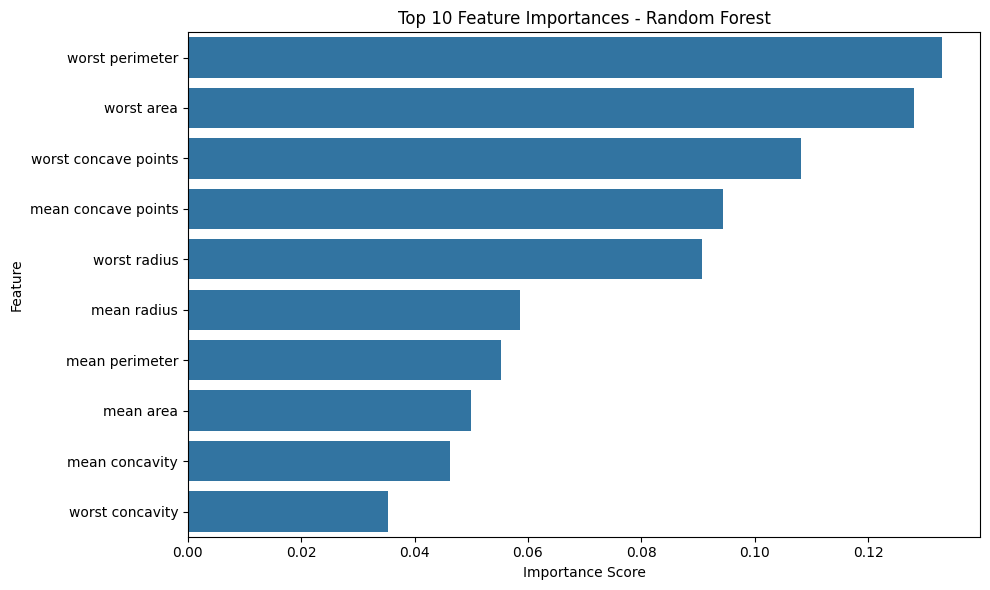

In [3]:

# STEP 3: Calculate and visualize feature importance

importances = model.feature_importances_

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Top 10 Most Important Features:")
display(importance_df.head(10))

# Plot the top 10 features
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Feature Importances - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [4]:

# STEP 4: Install SHAP

%pip install -q shap

print("SHAP installation completed!")


SHAP installation completed!


SHAP explanations generated successfully!


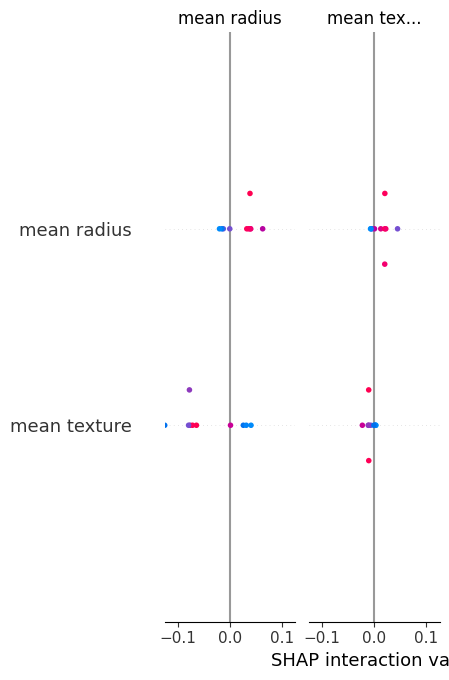

In [5]:

# STEP 5: Explain model predictions using SHAP

import shap

# Use a small sample to keep the explanation fast
X_background = X_train.sample(
    n=min(50, len(X_train)),
    random_state=42
)

X_explain = X_test.iloc[:10].copy()

# TreeExplainer is suitable for Random Forest models
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_explain)

print("SHAP explanations generated successfully!")

# Display SHAP summary plot
shap.summary_plot(
    shap_values,
    X_explain,
    feature_names=X.columns.tolist(),
    show=True
)


Class-wise model performance:


,Class,Precision,Recall,F1-score,Support
0,malignant,0.9512,0.9286,0.9398,42
1,benign,0.9589,0.9722,0.9655,72


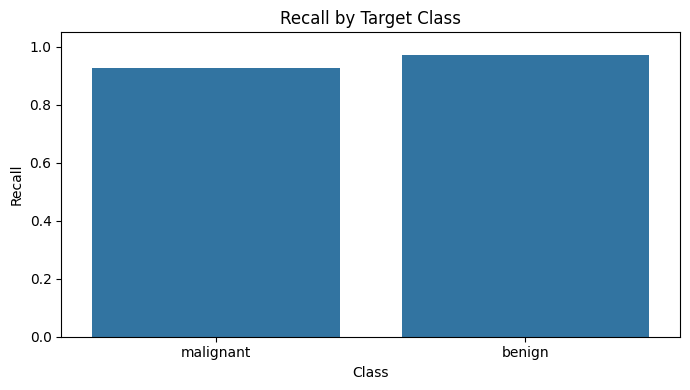

In [6]:

# STEP 6: Analyze class-wise performance

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

class_results = []

for class_id, class_name in enumerate(data.target_names):
    # Treat the current class as positive for one-vs-rest metrics
    y_true_binary = (y_test == class_id).astype(int)
    y_pred_binary = (y_pred == class_id).astype(int)

    class_results.append({
        "Class": class_name,
        "Precision": precision_score(
            y_true_binary, y_pred_binary, zero_division=0
        ),
        "Recall": recall_score(
            y_true_binary, y_pred_binary, zero_division=0
        ),
        "F1-score": f1_score(
            y_true_binary, y_pred_binary, zero_division=0
        ),
        "Support": int((y_test == class_id).sum())
    })

class_results_df = pd.DataFrame(class_results)

print("Class-wise model performance:")
display(class_results_df.round(4))

# Plot class-wise recall
plt.figure(figsize=(7, 4))
sns.barplot(
    data=class_results_df,
    x="Class",
    y="Recall"
)
plt.ylim(0, 1.05)
plt.title("Recall by Target Class")
plt.ylabel("Recall")
plt.tight_layout()
plt.show()


In [7]:

# STEP 7: Responsible AI assessment

fairness_assessment = pd.DataFrame([
    {
        "Risk": "Demographic bias",
        "Finding": "Demographic attributes are not available in this dataset.",
        "Mitigation": "Evaluate representative data with appropriate demographic attributes where lawful and ethically justified."
    },
    {
        "Risk": "Unequal class performance",
        "Finding": "Compare class-wise precision, recall and F1-score above.",
        "Mitigation": "Investigate errors for each class and validate any changes on separate data."
    },
    {
        "Risk": "Feature interpretation",
        "Finding": "Feature importance and SHAP explain model behavior, not causation.",
        "Mitigation": "Review explanations with domain experts and test their stability."
    },
    {
        "Risk": "High-stakes use",
        "Finding": "The model is trained on an educational dataset and is not clinically validated.",
        "Mitigation": "Do not use this model for medical diagnosis or treatment decisions."
    }
])

display(fairness_assessment)


,Risk,Finding,Mitigation
0,Demographic bias,Demographic attributes are not available in th...,Evaluate representative data with appropriate ...
1,Unequal class performance,"Compare class-wise precision, recall and F1-sc...",Investigate errors for each class and validate...
2,Feature interpretation,Feature importance and SHAP explain model beha...,Review explanations with domain experts and te...
3,High-stakes use,The model is trained on an educational dataset...,Do not use this model for medical diagnosis or...
